# Non-uniform allocation: one task's loss counts 10 times

When one task's loss counts 10 times, the best network gives that task more than half of the hidden units. Shadow
weights hand out units in proportion to outputs, so about half each. Do shadow weights then fall short of the best
split, and can simple generate and test move units to the task that needs them?

**Problem.** 2-task multi-MNIST as in `../05_multi_mnist.ipynb`: each sample concatenates 2 independently drawn 14×14
MNIST training images (per-pixel centered, one global scale), each task's target is its own image's label, and every
1000 steps one task (chosen at random) gets a new random mapping from digits to labels. The one change: the loss is
$10\,\text{CE}_A + \text{CE}_B$, so task A's (task 0's) softmax cross-entropy counts 10 times (with a 2× weight, the
even split had the lowest loss: commit 1a6c2e2). The learner minimizes this loss, and it is also the metric: the online
loss, averaged over the last 10% of training.

**Networks.** 392 inputs → 20 LTU hidden units → 20 linear outputs (2 groups of 10 logits), each layer with a bias.
- *Block-sparse, split k*: k hidden units read only task A's image and feed only its logits; the other 20 − k do the
  same for task B. k = 10 is the ideal connectivity of `../05_multi_mnist.ipynb`.
- *Fully connected*: every hidden unit reads every input and feeds every output.

**Learner.** Our method, as in `../05_multi_mnist.ipynb`: Autostep with $\alpha_0 = 10^{-8}$, meta step-size 0.01 and
$\tau = 10^4$, centered hidden units with a matching centered backward pass, and input weights starting at
$U(-\alpha_0, \alpha_0)$. Two add-ons, alone and together, in the fully connected network:
- *Shadow weights*, as in `../06_multi_mnist_8.ipynb`: each hidden unit is paired with a random output (any of the 20)
  and a random shadow weight of $+1$ or $-1$. In the backward pass a unit hears from every output through the output
  weights, as in backprop, except that the weight from its paired output counts as its shadow weight unless the real
  one is larger in magnitude. The forward pass is unchanged and the output weights keep their true gradients. About
  half the units are paired with each task.
- *Simple generate and test*, as in `../05_multi_mnist.ipynb`: every 100k steps, the hidden unit with the smallest mean
  $|$output weight$|$ starts over as a new unit: output weights 0, input weights $U(-\alpha_0, \alpha_0)$, step-sizes
  $\alpha_0$, zero Autostep traces, running means at their initial values, and with shadow weights a new random
  pairing and sign.

1M steps and 5 seeds; seed $s$ gives every run the same initial-weight draw, images and label changes, the same as
seed $s$ of `../05_multi_mnist.ipynb`. Plots show the mean $\pm$ 2 SE over seeds. Gaps are relative,
(loss − reference) / reference on each seed, given as the mean $\pm$ 2 SE over the paired seeds.

**Plan and hypotheses**, on the online loss averaged over the last 10% of training:
- *Step 1, the best split*: block-sparse with k = 10, 12, 14, 16 and 18. **H0** (precondition): the best k (lowest
  mean loss) is above 10. If H0 fails, the notebook stops after step 1.
- *Step 2a*: fully connected, with and without shadow weights, against the best split and the even split (k = 10).
  **H1**: shadow weights end more than 1% above the best split's loss.
- *Step 2b*: fully connected with simple generate and test, with and without shadow weights, shown with step 2a's runs
  and references. **H2**: adding generate and test to shadow weights lowers the loss by more than 1%.

The best split is picked on the same seeds it is then compared with, which favours it a little (H1 is slightly easier
to pass).

**Diagnostics**, fixed in advance:
1. For every run, each task's cross-entropy (CE$_A$ and CE$_B$) over the last 10% of training: what extra units gain
   task A and cost task B.
2. For the fully connected runs, the number of hidden units feeding task A over training, counting each unit for the
   task whose outputs it feeds most (by summed $|$output weight$|$), against the best k.

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from torchvision import datasets

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

sns.set_theme('notebook', 'white')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 2
N_PIXELS = 14 * 14                   # MNIST downsampled from 28x28 by averaging 2x2 blocks
N_CLASSES = 10
PERMUTE_PERIOD = 2000 // N_TASKS     # steps between label changes, each of one task chosen at random
TASK_WEIGHTS = (10.0, 1.0)           # the loss is 10 CE_A + CE_B: task A's (task 0's) cross-entropy counts 10 times

# --- Network ---
N_HIDDEN = 20
SPLITS = (10, 12, 14, 16, 18)        # step 1: task A's hidden units in the block-sparse networks; task B gets the rest

# --- Autostep ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 5                          # at most 30: seed s is seed s of 05_multi_mnist.ipynb
N_WINDOWS = 250                      # each window records its mean losses and the units feeding task A at its end

# --- Generate and test ---
RESET_PERIOD = 100_000               # steps between resets of the hidden unit with the smallest mean |output weight|

# --- Hypotheses ---
FINAL_FRACTION = 0.1                 # the loss is compared over the last 10% of training ...
LOSS_TOLERANCE = 0.01                # ... with this relative tolerance (1%)

In [3]:
mnist = datasets.MNIST(root='/tmp/data', train=True, download=True)
images = np.asarray(mnist.data, dtype=np.float32).reshape(-1, 14, 2, 14, 2).mean((2, 4)).reshape(-1, N_PIXELS) / 255.0
IMAGES = jnp.asarray((images - images.mean(0)) / images.std())     # per-pixel centered, one global scale
DIGITS = jnp.asarray(np.asarray(mnist.targets))


class Stream(NamedTuple):
    key: jax.Array
    step: jax.Array
    label_maps: jax.Array     # (task, digit): each task's current label for each digit


def init_stream(key):
    return Stream(key, jnp.array(0), jnp.tile(jnp.arange(N_CLASSES), (N_TASKS, 1)))


def next_sample(stream):
    # One sample: an independent training image per task, concatenated, and each task's label. Every PERMUTE_PERIOD
    # steps, one task chosen at random first gets a new random label mapping.
    key, task_key, map_key, image_key = jax.random.split(stream.key, 4)
    step = stream.step + 1
    changes = (step % PERMUTE_PERIOD == 0) & (jnp.arange(N_TASKS) == jax.random.randint(task_key, (), 0, N_TASKS))
    label_maps = jnp.where(changes[:, None], jax.random.permutation(map_key, N_CLASSES)[None], stream.label_maps)
    index = jax.random.randint(image_key, (N_TASKS,), 0, IMAGES.shape[0])
    labels = label_maps[jnp.arange(N_TASKS), DIGITS[index]]
    return Stream(key, step, label_maps), (IMAGES[index].reshape(-1), labels)

In [4]:
LAYERS = ('w1', 'w2')

input_task = np.repeat(np.arange(N_TASKS), N_PIXELS)
output_task = np.repeat(np.arange(N_TASKS), N_CLASSES)


def with_bias_column(mask):
    # The last column of each weight matrix reads the constant-1 input.
    return np.concatenate([mask, np.ones((mask.shape[0], 1), bool)], axis=1)


def block_sparse(k):
    # Masks shaped like the weight matrices (w1 is (hidden, inputs + 1), w2 is (outputs, hidden + 1)): the first k
    # hidden units read only task A's image and feed only its logits, the rest only task B's.
    hidden_task = (np.arange(N_HIDDEN) >= k).astype(int)
    return {'w1': with_bias_column(hidden_task[:, None] == input_task[None, :]),
            'w2': with_bias_column(output_task[:, None] == hidden_task[None, :])}


MASKS = {**{f'block-sparse, k = {k}': block_sparse(k) for k in SPLITS},
         'fully connected': {'w1': np.ones((N_HIDDEN, N_TASKS * N_PIXELS + 1), bool),
                             'w2': np.ones((N_TASKS * N_CLASSES, N_HIDDEN + 1), bool)}}

for name, masks in MASKS.items():
    print(f'{name}: ' + ', '.join(f'{k} {masks[k][:, :-1].sum():,} weights' for k in LAYERS))

block-sparse, k = 10: w1 3,920 weights, w2 200 weights
block-sparse, k = 12: w1 3,920 weights, w2 200 weights
block-sparse, k = 14: w1 3,920 weights, w2 200 weights
block-sparse, k = 16: w1 3,920 weights, w2 200 weights
block-sparse, k = 18: w1 3,920 weights, w2 200 weights
fully connected: w1 7,840 weights, w2 400 weights


## Learner

In [5]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Learner(NamedTuple):
    w: dict                   # {'w1': ..., 'w2': ...}; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState
    hidden_mean: jax.Array    # each hidden unit's running mean firing rate
    hidden_slope: jax.Array   # running mean of sigma'(z) x, each hidden unit's derivative w.r.t. each input weight
    pair: jax.Array           # each hidden unit's output for shadow weights ...
    sign: jax.Array           # ... and its fixed +-1 shadow weight from that output


def init_learner(key, masks):
    # Input weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE), output weights and biases 0.
    w1 = jax.random.uniform(key, masks['w1'].shape, minval=-1.0, maxval=1.0) * INIT_STEP_SIZE * masks['w1']
    w = {'w1': w1.at[:, -1].set(0.0), 'w2': jnp.zeros(masks['w2'].shape)}
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs, 1/4 for the bias.
    n_hidden, n_outputs = masks['w1'].shape[0], masks['w2'].shape[0]
    pair = jax.random.randint(jax.random.fold_in(key, 1), (n_hidden,), 0, n_outputs)
    sign = jax.random.rademacher(jax.random.fold_in(key, 2), (n_hidden,), dtype=jnp.float32)
    return Learner(w, OPTIMIZER.init(w), jnp.full(n_hidden, 0.5), jnp.zeros(masks['w1'].shape).at[:, -1].set(0.25),
                   pair, sign)


def forward(w, x, learner, masks, shadow=False):
    # Returns the prediction, each weight's source values (what Autostep normalizes by), and the new running means.
    x = jnp.append(x, 1.0)
    w1 = w['w1'] * masks['w1']
    z = w1 @ x
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = learner.hidden_mean + EMA_RATE * (jax.lax.stop_gradient(h) - learner.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))     # the LTU's surrogate slope
    slope = learner.hidden_slope + EMA_RATE * (sigma_prime[:, None] * x[None, :] - learner.hidden_slope)
    # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
    # correction leaves the value unchanged.
    correction = jnp.sum(slope * w1, axis=1)
    h = h - mean - correction + jax.lax.stop_gradient(correction)

    w2 = w['w2'] * masks['w2']
    if not shadow:
        y_hat = w2 @ jnp.append(h, 1.0)
    else:
        # Shadow weights: the outputs read h as usual, but h's gradient comes through a fixed matrix: the output
        # weights, except that the weight from each unit's paired output counts as its +-1 shadow weight unless the
        # real one is larger in magnitude. The last two terms cancel in value, and the output weights keep their true
        # gradient.
        units = jnp.arange(h.shape[0])
        paired = w2[learner.pair, units]
        feedback = jax.lax.stop_gradient(
            w2[:, :-1].at[learner.pair, units].set(jnp.where(jnp.abs(paired) > 1.0, paired, learner.sign)))
        y_hat = w2 @ jnp.append(jax.lax.stop_gradient(h), 1.0) + feedback @ h - jax.lax.stop_gradient(feedback @ h)
    return y_hat, ({'w1': x[None], 'w2': jnp.append(h, 1.0)[None]}, mean, slope)


def learner_step(learner, x, labels, masks, shadow=False):
    # One online Autostep update on the weighted loss, the sum of each task's cross-entropy times its weight in
    # TASK_WEIGHTS. Returns the new learner, the loss and each task's cross-entropy.
    def loss_fn(w):
        logits, aux = forward(w, x, learner, masks, shadow)
        ce = -jax.nn.log_softmax(logits.reshape(N_TASKS, N_CLASSES))[jnp.arange(N_TASKS), labels]
        return jnp.dot(jnp.array(TASK_WEIGHTS), ce), (aux, ce)

    (loss, ((source_values, mean, slope), ce)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    updates, opt = OPTIMIZER.update((grads, None, source_values), learner.opt, learner.w)
    w = {k: learner.w[k] + updates[k] for k in LAYERS}
    return learner._replace(w=w, opt=opt, hidden_mean=mean, hidden_slope=slope), loss, ce

## Training

In [6]:
WINDOW = NUM_STEPS // N_WINDOWS      # steps per window


def units_for_task_a(w):
    # The number of hidden units that feed task A most, by the summed |output weight| over each task's logits.
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, N_CLASSES, -1).sum(1)      # (task, unit)
    return jnp.sum(feeds.argmax(0) == 0)


def reset_units(learner, units, key, masks):
    # The hidden units marked in `units` start over as new units: their weights, step-sizes, Autostep traces, running
    # means and shadow pairing and sign are set to those of a freshly initialized network (output weights 0, input
    # weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE)).
    fresh = init_learner(key, masks)
    parts = {'w1': units[:, None], 'w2': jnp.append(units, False)[None, :]}         # their rows of w1, columns of w2
    pick = lambda new, old: {k: jnp.where(parts[k], new[k], old[k]) for k in LAYERS}
    opt = learner.opt
    return learner._replace(
        w=pick(fresh.w, learner.w),
        opt=opt._replace(beta=pick(fresh.opt.beta, opt.beta), h=pick(fresh.opt.h, opt.h), v=pick(fresh.opt.v, opt.v)),
        hidden_mean=jnp.where(units, fresh.hidden_mean, learner.hidden_mean),
        hidden_slope=jnp.where(units[:, None], fresh.hidden_slope, learner.hidden_slope),
        pair=jnp.where(units, fresh.pair, learner.pair), sign=jnp.where(units, fresh.sign, learner.sign))


def train(key, stream, masks, shadow=False, search=False):
    # Step 1 on its own, then NUM_STEPS online steps in windows. With `shadow`, the hidden units learn through shadow
    # weights (see forward()). With `search`, simple generate and test: at the end of every window that ends on a
    # multiple of RESET_PERIOD, the hidden unit with the smallest mean |output weight| starts over as a new unit.
    # Returns every window's mean loss and mean cross-entropy of each task, and the number of units feeding task A at
    # its end (before any reset).
    def one_step(carry, _):
        learner, stream = carry
        stream, (x, labels) = next_sample(stream)
        learner, loss, ce = learner_step(learner, x, labels, masks, shadow)
        return (learner, stream), (loss, ce)

    def window(carry, index):
        (learner, stream), (loss, ce) = jax.lax.scan(one_step, carry, length=WINDOW)
        record = {'loss': loss.mean(), 'ce': ce.mean(0), 'units_a': units_for_task_a(learner.w)}
        if search:
            unit = jnp.arange(N_HIDDEN) == jnp.argmin(jnp.abs(learner.w['w2'][:, :-1]).mean(0))
            reset = reset_units(learner, unit, jax.random.fold_in(key, index), masks)
            due = (index + 1) * WINDOW % RESET_PERIOD == 0
            learner = jax.tree.map(lambda new, old: jnp.where(due, new, old), reset, learner)
        return (learner, stream), record

    stream, (x, labels) = next_sample(stream)
    learner = learner_step(init_learner(key, masks), x, labels, masks, shadow)[0]
    return jax.lax.scan(window, (learner, stream), jnp.arange(N_WINDOWS))[1]


def run(network, shadow=False, search=False):
    # Trains our learner on `network` (a key of MASKS) on every seed, vmapped into one scan, with the add-ons of
    # train(). Seed s uses init key s and stream s of 05_multi_mnist.ipynb in every run, so runs are paired. Returns
    # per-seed records: loss and units feeding task A (seed, window), and ce (seed, window, task).
    keys = jax.random.split(jax.random.PRNGKey(0), 30)[:N_SEEDS]
    streams = jax.vmap(init_stream)(jax.random.split(jax.random.PRNGKey(1), 30)[:N_SEEDS])
    masks = MASKS[network]
    records = jax.jit(jax.vmap(lambda key, stream: train(key, stream, masks, shadow, search)))(keys, streams)
    return jax.tree.map(np.asarray, records)

## Step 1: the best split

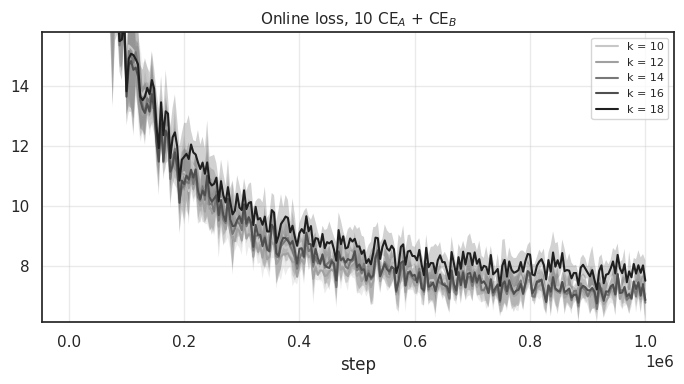

k = 10   online loss 7.228 (CE_A 0.655, CE_B 0.678), units feeding task A 10.0
k = 12   online loss 7.062 (CE_A 0.635, CE_B 0.717), units feeding task A 12.0
k = 14   online loss 7.132 (CE_A 0.637, CE_B 0.763), units feeding task A 14.0
k = 16   online loss 7.185 (CE_A 0.625, CE_B 0.934), units feeding task A 16.0
k = 18   online loss 7.805 (CE_A 0.622, CE_B 1.580), units feeding task A 18.0
gap, k = 12 vs k = 10: -2.22% (± 2.45)
gap, k = 14 vs k = 10: -1.29% (± 1.64)
gap, k = 16 vs k = 10: -0.60% (± 1.68)
gap, k = 18 vs k = 10: +8.02% (± 2.05)
H0, the best split is k = 12: held


In [7]:
window_ends = np.arange(1, N_WINDOWS + 1) * WINDOW
final = slice(-round(N_WINDOWS * FINAL_FRACTION), None)


def plot_runs(runs, colors, dashed=(), keys=('loss', 'units_a')):
    # The online loss and the units feeding task A (the `keys` of the records) over training for each run in `runs`
    # (mean +- 2 SE over seeds), drawn in `colors[label]`, and dashed for the labels in `dashed`. The loss axis is cut
    # at the highest mean loss after the first 10% of training.
    titles = {'loss': f'Online loss, {TASK_WEIGHTS[0]:g} CE$_A$ + CE$_B$', 'units_a': 'Hidden units feeding task A'}
    fig, axes = plt.subplots(1, len(keys), figsize=(7 * len(keys), 4), squeeze=False)
    for ax, key in zip(axes[0], keys):
        for label, res in runs.items():
            mean, sem = res[key].mean(0), res[key].std(0) / np.sqrt(N_SEEDS)
            ax.plot(window_ends, mean, color=colors[label], ls='--' if label in dashed else '-', lw=1.5, label=label)
            ax.fill_between(window_ends, mean - 2 * sem, mean + 2 * sem, color=colors[label], alpha=0.2, lw=0)
        ax.set_xlabel('step')
        ax.set_title(titles[key], fontsize=11)
        ax.grid(alpha=0.4)
    curves = [res['loss'].mean(0) for res in runs.values()]
    low, high = min(c.min() for c in curves), max(c[N_WINDOWS // 10:].max() for c in curves)
    axes[0, 0].set_ylim(low - 0.05 * (high - low), high + 0.05 * (high - low))
    axes[0, 0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()


def final_loss(res):
    return res['loss'][:, final].mean(1)                     # each seed's online loss over the last FINAL_FRACTION


def report(runs, tests):
    # Prints every run's online loss, each task's cross-entropy and the units feeding task A over the last
    # FINAL_FRACTION of training, then for each test (name, label, reference, claim) the relative gap of `label` to
    # `reference` (mean and 2 SE over paired seeds), and whether the claim held: more than LOSS_TOLERANCE 'above' or
    # 'below' it (no claim: None).
    width = max(map(len, runs))
    for label, res in runs.items():
        print(f'{label:<{width}}   online loss {final_loss(res).mean():.3f} (CE_A {res["ce"][:, final, 0].mean():.3f}, '
              f'CE_B {res["ce"][:, final, 1].mean():.3f}), units feeding task A {res["units_a"][:, final].mean():.1f}')
    for name, label, reference, claim in tests:
        g = final_loss(runs[label]) / final_loss(runs[reference]) - 1
        ok = g.mean() > LOSS_TOLERANCE if claim == 'above' else g.mean() < -LOSS_TOLERANCE
        verdict = '' if claim is None else f': {"held" if ok else "failed"}'
        print(f'{name}, {label} vs {reference}: {100 * g.mean():+.2f}% '
              f'(± {100 * 2 * g.std() / np.sqrt(N_SEEDS):.2f}){verdict}')


split_runs = {f'k = {k}': run(f'block-sparse, k = {k}') for k in SPLITS}
plot_runs(split_runs, dict(zip(split_runs, ('#c7c7c7', '#a0a0a0', '#787878', '#4f4f4f', '#1f1f1f'))), keys=('loss',))
report(split_runs, [('gap', label, 'k = 10', None) for label in split_runs if label != 'k = 10'])
best_k = min(SPLITS, key=lambda k: final_loss(split_runs[f'k = {k}']).mean())
print(f'H0, the best split is k = {best_k}: {"held" if best_k > 10 else "failed"}')

## Results, step 1

- **H0 held, but only on the mean.** k = 12 has the lowest loss, 7.062, against 7.228 for the even split (−2.22% ±
  2.45, 2 SE over paired seeds), 7.132 for k = 14 (−1.29% ± 1.64), 7.185 for k = 16 (−0.60% ± 1.68) and 7.805 for
  k = 18 (+8.02% ± 2.05). With 5 seeds, k = 12, 14 and 16 cannot be told apart from the even split; only k = 18 is
  clearly worse.
- **Per task**, over the last 10% (CE$_A$, CE$_B$): k = 10: 0.655, 0.678; k = 12: 0.635, 0.717; k = 14: 0.637, 0.763;
  k = 16: 0.625, 0.934; k = 18: 0.622, 1.580. Extra units gain task A little: 8 more lower CE$_A$ by 5%, and the first
  2 give most of that (3%). Units taken from task B cost more the fewer it keeps: CE$_B$ rises 6% with 8 units, 38%
  with 4 and 133% with 2. So even at 10× the best split is only slightly uneven, and close to the even split.

## Step 2a: shadow weights against the best split

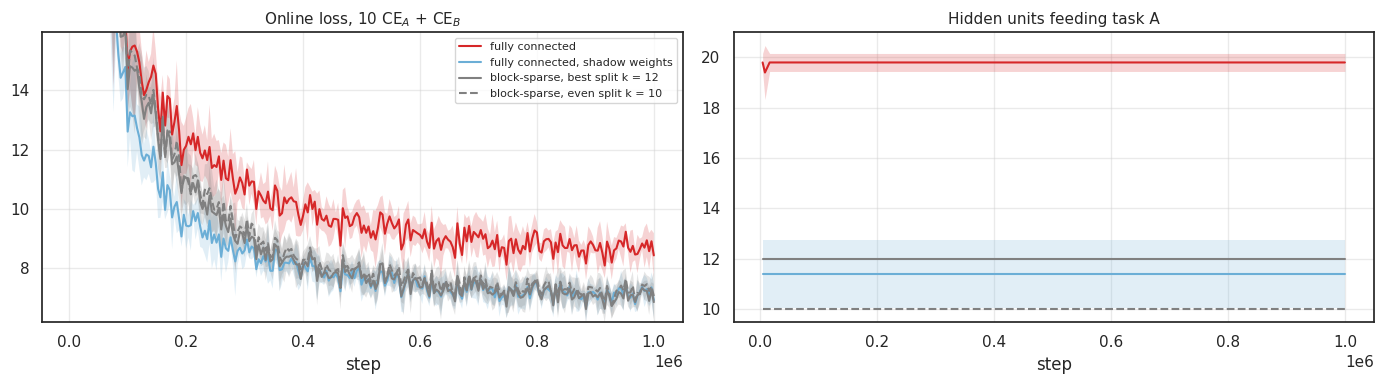

fully connected                   online loss 8.678 (CE_A 0.645, CE_B 2.226), units feeding task A 19.8
fully connected, shadow weights   online loss 7.134 (CE_A 0.642, CE_B 0.715), units feeding task A 11.4
block-sparse, best split k = 12   online loss 7.062 (CE_A 0.635, CE_B 0.717), units feeding task A 12.0
block-sparse, even split k = 10   online loss 7.228 (CE_A 0.655, CE_B 0.678), units feeding task A 10.0
H1, fully connected, shadow weights vs block-sparse, best split k = 12: +1.04% (± 3.19): held
gap, fully connected vs block-sparse, best split k = 12: +22.89% (± 2.13)
gap, fully connected, shadow weights vs block-sparse, even split k = 10: -1.25% (± 2.80)
gap, fully connected vs block-sparse, even split k = 10: +20.14% (± 2.69)


In [8]:
BEST, EVEN = f'block-sparse, best split k = {best_k}', 'block-sparse, even split k = 10'
references = {BEST: split_runs[f'k = {best_k}'], EVEN: split_runs['k = 10']}
COLORS = {'fully connected': 'tab:red', 'fully connected, shadow weights': '#6baed6',
          'fully connected, generate and test': '#3182bd',
          'fully connected, shadow weights + generate and test': '#08519c', BEST: 'gray', EVEN: 'gray'}

fc_runs = {'fully connected': run('fully connected'),
           'fully connected, shadow weights': run('fully connected', shadow=True)}
plot_runs({**fc_runs, **references}, COLORS, dashed=[EVEN])
report({**fc_runs, **references}, [('H1', 'fully connected, shadow weights', BEST, 'above'),
                                   ('gap', 'fully connected', BEST, None),
                                   ('gap', 'fully connected, shadow weights', EVEN, None),
                                   ('gap', 'fully connected', EVEN, None)])

## Results, step 2a

- **H1 held, but not clearly.** Shadow weights end at 7.134, +1.04% (± 3.19) above the best split (7.062): just over
  the 1% threshold, and well within the noise. They are −1.25% (± 2.80) against the even split (7.228). Their
  per-task losses (CE$_A$ 0.642, CE$_B$ 0.715) are close to the best split's (0.635, 0.717).
- **Diagnostic.** Shadow weights keep about 11.4 units on task A (their random pairings' share), flat from the start;
  the best split has 12.
- Fully connected, our method gives nearly every unit to task A: 19.8 of 20 feed it from the first 10k steps on, and
  the count stays there. Task B is left near chance (CE$_B$ 2.226; chance is ln 10 ≈ 2.303), so the loss is 8.678,
  +22.89% (± 2.13) above the best split.
- Shadow weights also learn faster: their loss is below both block-sparse networks' until about 350k steps (plot).

## Step 2b: adding simple generate and test

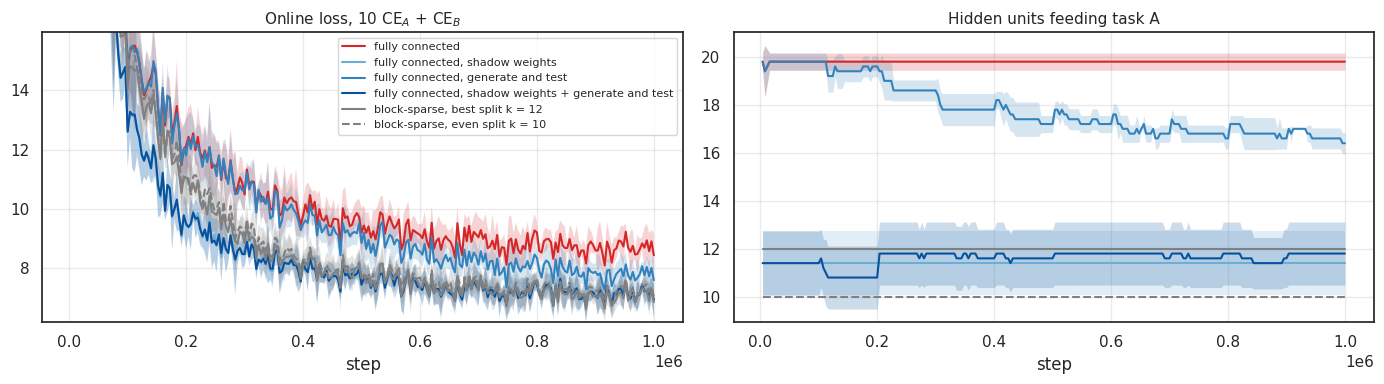

fully connected                                       online loss 8.678 (CE_A 0.645, CE_B 2.226), units feeding task A 19.8
fully connected, shadow weights                       online loss 7.134 (CE_A 0.642, CE_B 0.715), units feeding task A 11.4
fully connected, generate and test                    online loss 7.778 (CE_A 0.645, CE_B 1.332), units feeding task A 16.7
fully connected, shadow weights + generate and test   online loss 7.143 (CE_A 0.642, CE_B 0.719), units feeding task A 11.8
block-sparse, best split k = 12                       online loss 7.062 (CE_A 0.635, CE_B 0.717), units feeding task A 12.0
block-sparse, even split k = 10                       online loss 7.228 (CE_A 0.655, CE_B 0.678), units feeding task A 10.0
H2, fully connected, shadow weights + generate and test vs fully connected, shadow weights: +0.14% (± 1.23): failed
gap, fully connected, generate and test vs fully connected: -10.36% (± 1.78)
gap, fully connected, generate and test vs block-sparse, best s

In [9]:
search_runs = {'fully connected, generate and test': run('fully connected', search=True),
               'fully connected, shadow weights + generate and test': run('fully connected', shadow=True, search=True)}
all_runs = {**fc_runs, **search_runs, **references}
plot_runs(all_runs, COLORS, dashed=[EVEN])
report(all_runs, [('H2', 'fully connected, shadow weights + generate and test', 'fully connected, shadow weights',
                   'below'),
                  ('gap', 'fully connected, generate and test', 'fully connected', None),
                  ('gap', 'fully connected, generate and test', BEST, None),
                  ('gap', 'fully connected, shadow weights + generate and test', BEST, None)])

## Results, step 2b

- **H2 failed.** Adding generate and test to shadow weights changes the loss by +0.14% (± 1.23): 7.143 against
  7.134. The units feeding task A go from 11.4 to 11.8 (best split: 12). It ends +1.15% (± 2.61) above the best split.
- Without shadow weights, generate and test moves units the other way, to the starved task B: the units feeding task A
  fall in steps at the resets, from 19.8 to 16.7 (last 10%; still falling at 1M steps), and the loss falls
  10.36% (± 1.78), to 7.778 (CE$_B$ 1.332). That is still +10.12% (± 1.35) above the best split. (A reset unit with
  near-zero output weights counts for whichever task they favour, so these counts are noisy by about one unit.)
- So on this problem shadow weights lose little by splitting about evenly, because the best split is close to even;
  and simple generate and test moved units only where a task was starved (task B, without shadow weights), and
  barely changed the split of shadow weights.